In [61]:
import json
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. API-аас дата татах (requests сан шаардахгүй urllib ашиглав)
url = "https://archive-api.open-meteo.com/v1/archive?latitude=47.9077&longitude=106.8832&start_date=2025-01-01&end_date=2025-12-31&daily=temperature_2m_mean,relative_humidity_2m_mean,cloud_cover_mean,precipitation_sum&timezone=Asia/Ulaanbaatar"

with urllib.request.urlopen(url) as response:
    data = json.loads(response.read().decode())

df = pd.DataFrame(data['daily'])

# 2. Төрөл хувиргалт болон Хэмжигдэхүүн (Chi загвар - Үнэ цэнэ)
df['time'] = pd.to_datetime(df['time'])
df['cloud_cover_okta'] = (df['cloud_cover_mean'] / 100) * 8  # %-ийг 0-8 okta руу шилжүүлэх

# 3. Улирлаар бүлэглэх (Chi загвар - Шинжилгээний ангилал)
def get_season(month):
    if month in [12, 1, 2]: return 'Өвөл'
    elif month in [3, 4, 5]: return 'Хавар'
    elif month in [6, 7, 8]: return 'Зун'
    else: return 'Намар'

df['Season'] = df['time'].dt.month.apply(get_season)

# 4. Өгөгдлийн чанарын шалгалт
print("--- ӨГӨГДЛИЙН ЧАНАРЫН ШАЛГАЛТ ---")
assert len(df) == 365, f"Алдаа: 365 өдөр байх ёстойгоос {len(df)} байна."
print(f"Хоосон утгын тоо:\n{df.isna().sum()}\n")
print("Үндсэн статистик үзүүлэлтүүд:\n", df[['temperature_2m_mean', 'relative_humidity_2m_mean', 'precipitation_sum', 'cloud_cover_okta']].describe().round(1))

--- ӨГӨГДЛИЙН ЧАНАРЫН ШАЛГАЛТ ---
Хоосон утгын тоо:
time                         0
temperature_2m_mean          0
relative_humidity_2m_mean    0
cloud_cover_mean             0
precipitation_sum            0
cloud_cover_okta             0
Season                       0
dtype: int64

Үндсэн статистик үзүүлэлтүүд:
        temperature_2m_mean  relative_humidity_2m_mean  precipitation_sum  \
count                365.0                      365.0              365.0   
mean                   0.7                       59.5                0.8   
std                   14.6                       15.0                2.7   
min                  -28.2                       22.0                0.0   
25%                  -12.7                       48.0                0.0   
50%                    3.2                       62.0                0.0   
75%                   13.8                       72.0                0.4   
max                   26.4                       90.0               29.7   

 

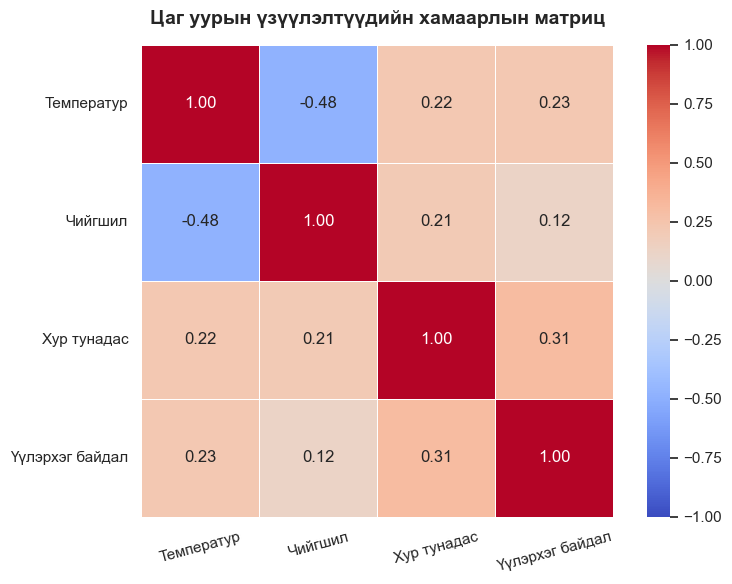

In [ ]:

plt.figure(figsize=(8, 6))

numeric_cols = ['temperature_2m_mean', 'relative_humidity_2m_mean', 'precipitation_sum', 'cloud_cover_okta']
corr_matrix = df[numeric_cols].corr()

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".2f", 
            linewidths=0.5, square=True)

plt.title('Цаг уурын үзүүлэлтүүдийн хамаарлын матриц', fontsize=14, fontweight='bold', pad=15)

# Тэнхлэгийн нэрийг ойлгомжтойгоор солих
labels = ['Температур', 'Чийгшил', 'Хур тунадас', 'Үүлэрхэг байдал']
plt.xticks(ticks=np.arange(4) + 0.5, labels=labels, rotation=15)
plt.yticks(ticks=np.arange(4) + 0.5, labels=labels, rotation=0)

plt.tight_layout()
plt.show()

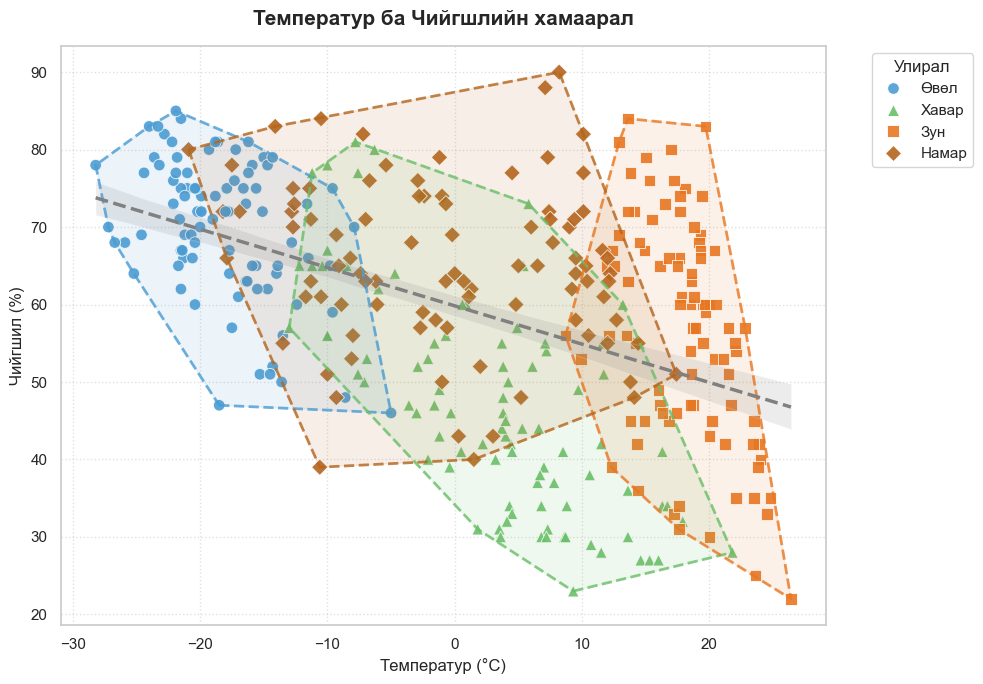

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.spatial import ConvexHull

# Өнгөний тохиргоо
season_palette = {'Өвөл': '#4B9CD3', 'Хавар': '#6ABF69', 'Зун': '#E87722', 'Намар': '#B5651D'}
markers = {'Өвөл': 'o', 'Хавар': '^', 'Зун': 's', 'Намар': 'D'} # Зурагт байсан дүрсүүдийг ашиглах

plt.figure(figsize=(10, 7))

# 1. Үндсэн Scatter plot (Дүрс болон өнгөөр ялгасан)
sns.scatterplot(
    data=df, 
    x='temperature_2m_mean', 
    y='relative_humidity_2m_mean', 
    hue='Season', 
    style='Season',     # Дүрсээр ялгах
    markers=markers, 
    palette=season_palette,
    s=70, alpha=0.9, edgecolor='white'
)


for season in df['Season'].unique():
    points = df[df['Season'] == season][['temperature_2m_mean', 'relative_humidity_2m_mean']].values
    
    if len(points) >= 3:
        hull = ConvexHull(points)
        vertices = np.append(hull.vertices, hull.vertices[0])
        
        plt.plot(points[vertices, 0], points[vertices, 1], 
                 color=season_palette[season], lw=2, linestyle='--', alpha=0.8)
        
        # Хүрээн доторх хэсгийг бүдэг өнгөөр будах (заавал биш, гэхдээ илүү гоё харагдана)
        plt.fill(points[vertices, 0], points[vertices, 1], 
                 color=season_palette[season], alpha=0.1)
# 3. Чиг хандлагын шугам (Trend line / Regression line) нэмэх
sns.regplot(
    data=df, 
    x='temperature_2m_mean', 
    y='relative_humidity_2m_mean', 
    scatter=False,       # Scatter-ийг давхар зурахгүй, зөвхөн шугамыг зурах
    color='gray',        # Саарал өнгөтэй
    line_kws={'linestyle':'--', 'linewidth':2.5, 'zorder':10}, # Тасархай зураастай, бусад дүрснээс дээр гаргах (zorder)
)
# Ерөнхий тохиргоо
plt.title('Температур ба Чийгшлийн хамаарал', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Температур (°C)', fontsize=12)
plt.ylabel('Чийгшил (%)', fontsize=12)
plt.legend(title='Улирал', bbox_to_anchor=(1.05, 1), loc='upper left') # Тайлбарыг баруун талд гаргах
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

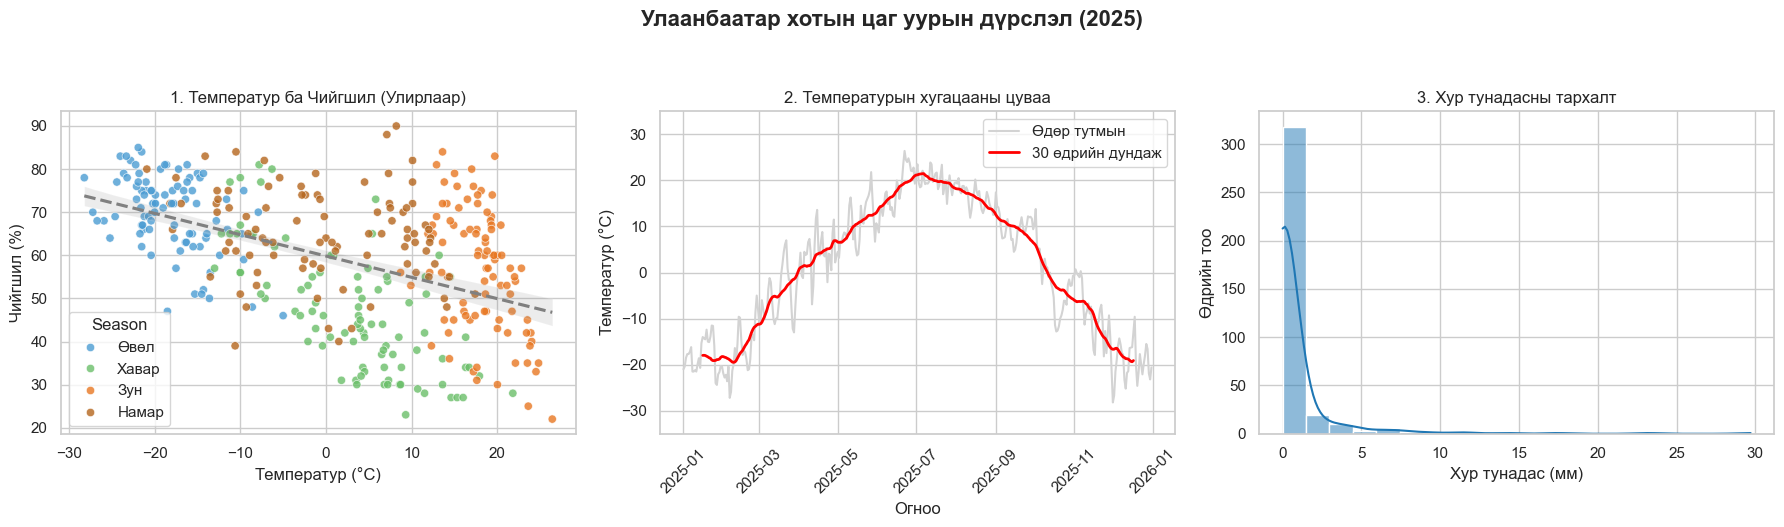

In [64]:
# Даалгаврын шаардлагын дагуух өнгөний схем
season_palette = {'Өвөл': '#4B9CD3', 'Хавар': '#6ABF69', 'Зун': '#E87722', 'Намар': '#B5651D'}

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Улаанбаатар хотын цаг уурын дүрслэл (2025)', fontsize=16, fontweight='bold', y=1.05)

# 1. Scatter: Температур vs Чийгшил (Улирлаар)
sns.scatterplot(data=df, x='temperature_2m_mean', y='relative_humidity_2m_mean', 
                hue='Season', palette=season_palette, ax=axes[0], alpha=0.8)
sns.regplot(data=df, x='temperature_2m_mean', y='relative_humidity_2m_mean', 
            scatter=False, color='gray', ax=axes[0], line_kws={"linestyle": "--"})
axes[0].set_title('1. Температур ба Чийгшил (Улирлаар)', fontsize=12)
axes[0].set_xlabel('Температур (°C)')
axes[0].set_ylabel('Чийгшил (%)')

# 2. Line chart: Температурын цуваа (Rolling mean-тэй)
sns.lineplot(data=df, x='time', y='temperature_2m_mean', ax=axes[1], color='lightgray', label='Өдөр тутмын')
df['temp_rolling_30'] = df['temperature_2m_mean'].rolling(window=30, center=True).mean()
sns.lineplot(data=df, x='time', y='temp_rolling_30', ax=axes[1], color='red', linewidth=2, label='30 өдрийн дундаж')
axes[1].set_title('2. Температурын хугацааны цуваа')
axes[1].set_xlabel('Огноо')
axes[1].set_ylabel('Температур (°C)')
axes[1].set_ylim(-35, 35) # Хязгаар тогтоох
axes[1].tick_params(axis='x', rotation=45)

# 3. Histogram: Хур тунадасны тархалт
sns.histplot(data=df, x='precipitation_sum', bins=20, kde=True, ax=axes[2], color='#1f77b4')
axes[2].set_title('3. Хур тунадасны тархалт')
axes[2].set_xlabel('Хур тунадас (мм)')
axes[2].set_ylabel('Өдрийн тоо')

plt.tight_layout()
plt.show()

Илрүүлсэн аномалийн тоо (Температурын хэлбэлзэл): 0 өдөр



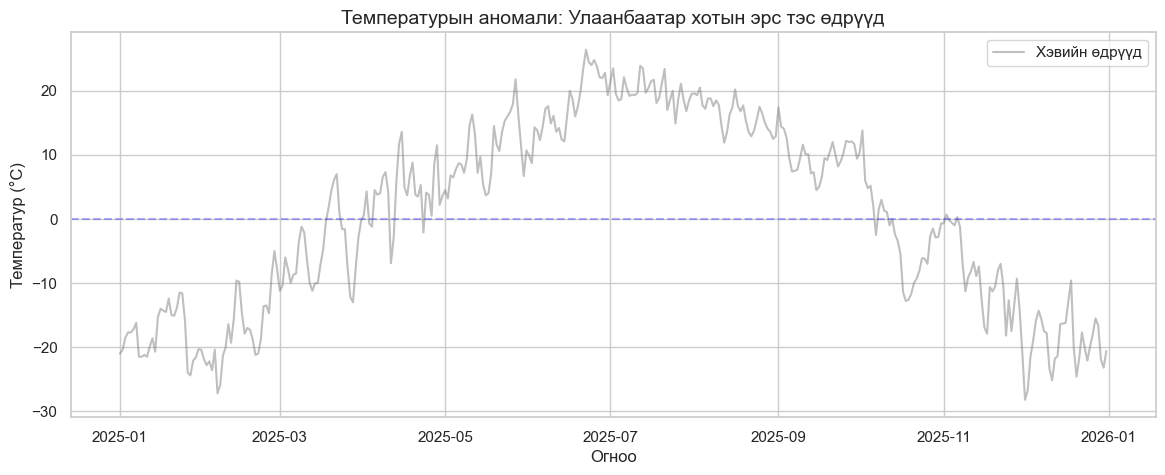

Хур тунадасны тархалтын онцлог: Нийт 137 бороо/цастай өдөр, 228 хуурай өдөр (Zero-inflated).


In [65]:
# IQR болон Z-score ашиглан температурын outlier олох
df['temp_zscore'] = (df['temperature_2m_mean'] - df['temperature_2m_mean'].mean()) / df['temperature_2m_mean'].std()

# Z-score > 2 эсвэл < -2 байвал аномали гэж үзнэ
anomalies = df[df['temp_zscore'].abs() > 2.0]

print(f"Илрүүлсэн аномалийн тоо (Температурын хэлбэлзэл): {len(anomalies)} өдөр\n")

# Аномалийг график дээр тодруулах
plt.figure(figsize=(14, 5))
sns.lineplot(data=df, x='time', y='temperature_2m_mean', color='gray', alpha=0.5, label='Хэвийн өдрүүд')
sns.scatterplot(data=anomalies, x='time', y='temperature_2m_mean', color='red', s=80, edgecolor='black', zorder=5, label='Аномали (Outlier)')

plt.title('Температурын аномали: Улаанбаатар хотын эрс тэс өдрүүд', fontsize=14)
plt.xlabel('Огноо')
plt.ylabel('Температур (°C)')
plt.axhline(0, color='blue', linestyle='--', alpha=0.3)
plt.legend()
plt.show()

# Бороотой болон хуурай өдрийн харьцааг тооцох
rainy_days = len(df[df['precipitation_sum'] > 0])
dry_days = 365 - rainy_days
print(f"Хур тунадасны тархалтын онцлог: Нийт {rainy_days} бороо/цастай өдөр, {dry_days} хуурай өдөр (Zero-inflated).")

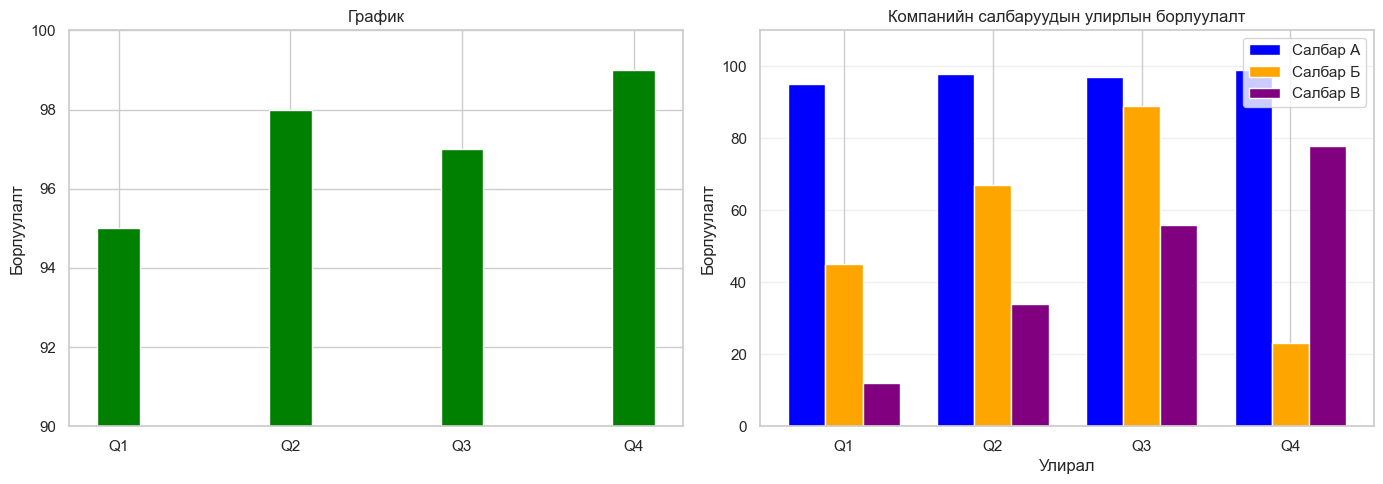

In [66]:

import matplotlib.pyplot as plt
import numpy as np

# Өгөгдөл
quarters = ["Q1", "Q2", "Q3", "Q4"]

sales = {
    "А": [95, 98, 97, 99],
    "Б": [45, 67, 89, 23],
    "В": [12, 34, 56, 78]
}

# График байгуулах
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

x = np.arange(len(quarters))
width = 0.25

# 1. Муу дүрслэл
for branch, values in sales.items():
    ax[0].bar(x, values, width, color="green")

ax[0].set_ylim(90, 100)
ax[0].set_title("График")
ax[0].set_xticks(x)
ax[0].set_xticklabels(quarters)
ax[0].set_ylabel("Борлуулалт")

# 2. Сайжруулсан дүрслэл
colors = ["blue", "orange", "purple"]

for i, (branch, values) in enumerate(sales.items()):
    ax[1].bar(
        x + (i - 1) * width,
        values,
        width,
        color=colors[i],
        label="Салбар " + branch
    )

ax[1].set_ylim(0, 110)
ax[1].set_title("Компанийн салбаруудын улирлын борлуулалт")
ax[1].set_xlabel("Улирал")
ax[1].set_ylabel("Борлуулалт")
ax[1].set_xticks(x)
ax[1].set_xticklabels(quarters)
ax[1].legend()
ax[1].grid(axis="y", alpha=0.3)
ax[1].set_axisbelow(True)

plt.tight_layout()
plt.show()
